# PPO Modèle

Ce notebook sert à l'initialisation et à l'entraînement du modèle PPO à l'atterrissage du module lunaire.
Le PPO (Proximal Policy Optimization) est un algorithme d'apprentissage par renforcement (Reinforcement Learning). Contrairement au DQN, qui cherche à estimer la valeur de chaque action possible grâce à un réseau de neurones, le PPO apprend directement une politique qui détermine quelles actions effectuer selon l'état actuel de l'environnement.
Il utilise deux réseaux de neurones complémentaires :

- L'Actor : il détermine la probabilité de choisir chacune des actions possibles.
- Le Critic : il estime la valeur d'un état afin d'aider l'Actor à améliorer ses décisions.

L'objectif est d'apprendre progressivement une politique capable de faire atterrir le module lunaire de manière autonome et efficace.

# Import

Nous importons dans cette section toutes les bibliothèques qui nous seront utiles pour effectuer l'entraînement du modèle PPO, manipuler les réseaux de neurones, gérer les expériences et analyser les résultats obtenus.

In [22]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Environnement agent aléatoire

Afin d'appréhender le fonctionnement de l'environnement LunarLander et les possibilités offertes par l'apprentissage par renforcement, nous effectuons un premier essai avec un agent aléatoire.
Cet agent sélectionne ses actions sans aucune stratégie particulière. Cela nous permet d'observer les récompenses obtenues et de comprendre les difficultés rencontrées par le module lunaire.
Cette première expérience servira de référence pour comparer les performances obtenues avec notre modèle PPO entraîné.
Nous récupérons également les dimensions de l'environnement :

- Le nombre de valeurs composant l'état du module : 8.
- Le nombre d'actions possibles : 4.

In [23]:
env = gym.make("LunarLander-v3")

#récupération de l'environnement et des actions
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

# print(state_dim)
# print(action_dim)

# Test de l'agent aléatoire
state, info = env.reset(seed=42)
total_reward = 0.0
done = False
steps = 0

while not done:
    # l'agent choisit une action au hasard
    action = env.action_space.sample()
    
    # on applique l'action
    next_state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    steps += 1
    
    # l'épisode est fini si le vaisseau s'écrase, atterrit terminated ou atteint la limite de temps truncated
    done = terminated or truncated

print(f"Score de l'agent aléatoire : {total_reward:.1f} (en {steps} étapes)")
env.close()



Score de l'agent aléatoire : -87.0 (en 115 étapes)


On voit que les résultats ne sont pas très bons : le modèle faisant des actions aléatoirement ne possède aucune stratégie lui permettant de contrôler efficacement sa trajectoire.
Cet essai montre l'intérêt de l'apprentissage par renforcement : l'agent doit apprendre à partir des récompenses reçues afin d'améliorer progressivement ses décisions.

# Actor/Critic initialisation

Nous commençons par construire l'architecture de notre modèle PPO.
Contrairement au DQN, qui utilise un seul réseau pour estimer les valeurs Q des différentes actions, le PPO utilise deux réseaux complémentaires : l'Actor et le Critic.

<b> L'Actor : </b>

Il reçoit les 8 valeurs représentant l'état du module lunaire et les transmet à deux couches cachées de 64 neurones utilisant la fonction d'activation Tanh.
La dernière couche produit 4 valeurs correspondant aux différentes actions possibles.
Ces valeurs sont appelées logits. Elles sont ensuite utilisées pour construire une distribution de probabilités permettant de sélectionner une action.

<b>Le Critic : </b>

Il possède une architecture similaire à celle de l'Actor, avec deux couches cachées de 64 neurones et une fonction d'activation Tanh.
Sa dernière couche ne produit cependant qu'une seule valeur : l'estimation de la valeur de l'état actuel.
Cette estimation permet de comparer les résultats réellement obtenus avec ceux attendus et aide ainsi l'Actor à améliorer sa politique.
Les deux réseaux sont regroupés dans une même classe ActorCritic, ce qui permet de récupérer leurs sorties simultanément.

In [24]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(ActorCritic, self).__init__()


        # ce réseau va permettre de donner une probabiltié de la prochaine action a réaliser selon l'env du vaisseau
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64), # prend nos 8 valeurs d'entrées et les envoie dans une couche de 64 neuronnes
            nn.Tanh(), # convertit nos donneés entre -1 et 1 pour une meilleur exploitation 
            nn.Linear(64, 64), # on refournit nos données déjà entrainé sur nos 64 neuronnes dnas 64 nouveaux neurones une couche de plus
            nn.Tanh(),
            nn.Linear(64, action_dim) # output des 4 actions
        )
        
        # sort une seule valeur estimation de l'action
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1) 
        )
        

    #  cet fonction permet de choisir le chemin que la donnée va suivre dans notre réseau de neuronne
    def forward(self, state):
        action_probs = self.actor(state)
        state_value = self.critic(state)
        return action_probs, state_value


# Rollout buffer

Le Rollout Buffer est un système de stockage temporaire des expériences collectées par notre agent PPO.

Contrairement au Replay Buffer du DQN, qui conserve des expériences pouvant être réutilisées aléatoirement, le Rollout Buffer stocke les expériences récentes afin de les utiliser pour les prochaines mises à jour du modèle.

Il conserve plusieurs informations importantes :

- States : les états rencontrés par le module lunaire.
- Actions : les actions sélectionnées par l'Actor.
- Rewards : les récompenses obtenues après chaque action.
- Is_terminals : indique si l'épisode est terminé.
- Certitude : conserve les anciennes log-probabilités des actions sélectionnées.
- State_values : conserve les valeurs estimées par le Critic au moment de la sélection des actions.

Les anciennes log-probabilités sont particulièrement importantes : elles permettent de comparer la politique actuelle avec celle qui avait été utilisée pour collecter les expériences.

Une fois les expériences utilisées pour mettre à jour le modèle, la fonction clear() vide le buffer afin de pouvoir collecter de nouvelles données.

In [25]:
class RolloutBuffer:
    def __init__(self):

        #données de l'environnement
        self.states =[]
        self.actions=[]
        self.rewards= []
        self.is_terminals= []

        # nous indiquera a quel point la politique a changé
        # si par exemple après l'action il est sur a 80% de l'action faites, on comparera avec a quel point il est sur apres mise a jour de la politique genre si 90%
        # on fera 90/80 qui donnera 1.125 donc une estimation de a quel point la politique a changé
        self.certitude= []

        # sauvegarde du v(s) du critique au moment de l'action
        self.state_values= []


    def clear(self):

        del self.states[:]
        del self.actions[:]
        del self.rewards[:]
        del self.is_terminals[:]
        del self.certitude[:]
        del self.state_values[:]

buffer = RolloutBuffer()




# GAE

Le GAE (Generalized Advantage Estimation) permet de calculer les avantages associés aux actions effectuées par notre agent.

L'avantage permet de savoir si une action a produit un résultat meilleur ou moins bon que ce que le Critic avait estimé.

Pour cela, nous comparons les récompenses obtenues avec les valeurs estimées par le Critic.

Nous utilisons notamment deux paramètres :

- Gamma (0.999) : détermine l'importance accordée aux récompenses futures par rapport aux récompenses immédiates.
- GAE Lambda (0.98) : permet de contrôler le compromis entre les estimations des avantages et leur stabilité.

Le calcul commence par déterminer le delta, qui représente la différence entre la récompense réellement obtenue, la valeur estimée de l'état suivant et la valeur estimée de l'état actuel.

Le GAE combine ensuite ces différences successives en remontant les expériences dans l'ordre inverse.

Nous obtenons finalement deux listes :

- Advantages : les avantages calculés pour chaque expérience.
- Returns : les valeurs cibles utilisées pour entraîner le Critic.

Ces informations permettent à l'Actor de savoir quelles actions doivent être favorisées et au Critic d'améliorer ses estimations.

In [26]:
#  gamma indique que l'agent doit valoriser les récompenses futures presque autant que les récompenses immédiates
#   gae lambda va permettre de stabiliser lentrainement
def compute_gae(buffer, gamma=0.99, gae_lambda=0.98):

    advantages = [] # *on va ranger la note finale de chaque action + ou -
    returns = []    #  on va ranger le score réel total de l'action
    gae = 0   

    for step in reversed(range(len(buffer.rewards))):
        is_terminal = buffer.is_terminals[step] # on observe si le vaisseau a termné l'action, crashé ou pas

        if step == len(buffer.rewards) -1 or is_terminal: # si on est l'index de la fin des éléments ou que l'action est terminée
            next_value = 0 # il n'a donc plus de donneés ou c'est arreté donc plus d'état suivant, on fixe alors la valeur a 0
        else:
            # si on est pas au derniere éléments ou que l'acction n'est pas terminé alors on est en plein vol ou pleine action du vaisseau 
            # on récupère alors la valeurs que le critique nous renvoie 
            # sans .item on aurait une donnée tensor illisible donc on item pour avori un chiffre basique
            next_value = buffer.state_values[step + 1].item()

        # on récupère l'ancienne valeur du critique
        current_value = buffer.state_values[step].item()

        # si next_value est plus grand que current value alors on considère que l'action faite dans le futur est meilleur que celle du passé

        # CALCULE DE LA SURPRISE -> décalage entre l'estimation du critique et la vérité 
        # delta prend la récompense immédiate
        delta = buffer.rewards[step] + gamma * next_value - current_value

        # gae prend lisse les résultats pour avoir une estimation de la précision du critique général
        
        # vérification, si la parti est terminé on remet notre gae a 0
        if is_terminal:
            gae = 0
            
        # surprise immédiate + ce qui se passe dans le futur
        # imagine que sur un instant T on coupe le moteur, l'ia va dire "cool on économise du carburant + 5 récompenses" mais
        # sur le futur ca va litéralement tuer la trajectoire et il se crash, donc l'action a l'instant T est bonne mais par 
        # la suite on doit prendre en compte le fait vaisseau se crash.
        gae = delta + gamma * gae_lambda * gae


        
        advantages.insert(0,gae)

        # return correspond à notre prédiction du critique + le bonus ou malus de l'action 
        returns.insert(0,gae+ current_value)
    return advantages ,returns

# PPO initialisation -> injection de l'actor/critique

Nous créons maintenant notre agent PPO en regroupant les deux réseaux précédemment définis.

La classe PPOAgent contient notre modèle ActorCritic ainsi que son optimiseur Adam.

Elle possède deux fonctions principales :

<b>Select_action :</b>

Cette fonction permet à l'agent de choisir une action selon l'état actuel du module lunaire.

L'Actor produit des logits qui sont transformés en distribution de probabilités grâce à Categorical.

Nous utilisons ensuite sample() pour sélectionner une action selon cette distribution.

Cela permet à l'agent de ne pas toujours choisir l'action ayant la probabilité la plus élevée pendant l'entraînement.

Nous enregistrons également dans le Rollout Buffer l'état, l'action sélectionnée, son ancienne log-probabilité et la valeur estimée par le Critic.

In [27]:
class PPOAgent:
    def __init__(self, state_dim,action_dim, lr= 0.0003): # convention d'apprentissage classique - si trop petit alors on aurait besoin de 10k d'épisodes
        self.policy = ActorCritic(state_dim, action_dim).to(device)

        #optimiseur
        self.optimizer = optim.Adam(self.policy.parameters(), lr=lr)

    def select_action(self, state, buffer):
        #conversion de notre environnement en tensor pytorch exploitable
        state = torch.FloatTensor(state).to(device)

        with torch.no_grad():
            action_probs, state_value = self.policy(state)


        # instancier les probabilités choisies par le modèle 
        dist = Categorical(logits=action_probs)

        # va permettre de choisir l'action selon les probabilités renvoyés 
        # genre si on a 0.1 0.5 0.2 0.2 ya 50% de chance que le modele choisisse l'action 2 
        action = dist.sample()


        # remplir le buffer
        buffer.states.append(state)
        buffer.actions.append(action)
        buffer.certitude.append(dist.log_prob(action))
        buffer.state_values.append(state_value)

        return action.item()

    def update(self, buffer, epochs=10, batch_size=64, epsilon=0.2): # epochs -> révision sur le meme buffer, batch_size -> paquets de step sur lequels ils s'entrainent
        # epsilon -> clipping du modèle, lempeche de changer brutalement de politique si il trouve une super action 
        
        # récupération et transformation en tensor de l'action précédentes
        old_states = torch.squeeze(torch.stack(buffer.states, dim=0)).detach().to(device)
        old_actions = torch.squeeze(torch.stack(buffer.actions, dim=0)).detach().to(device)
        old_logprobs = torch.squeeze(torch.stack(buffer.certitude, dim=0)).detach().to(device)

        advantages, returns = compute_gae(buffer)
        advantages = torch.tensor(advantages, dtype=torch.float32).to(device)
        returns = torch.tensor(returns, dtype=torch.float32).to(device)

        buffer_size = len(buffer.states)
        indices = np.arange(buffer_size)

        # 2. Boucle d'entrainement par mini-batch
        for _ in range(epochs):
            np.random.shuffle(indices) # melanger les données
            
            for start in range(0, buffer_size, batch_size):
                end = start + batch_size
                mb_indices = indices[start:end] # va contenir donc un petit paquet de 64 états

                # Extraction des différentes data des 64 états
                mb_states = old_states[mb_indices]
                mb_actions = old_actions[mb_indices] # 0 1 2 3
                mb_logprobs = old_logprobs[mb_indices] # cest la certitude du critique AU MOMENT DE L'ACTION
                mb_advantages = advantages[mb_indices]
                mb_returns = returns[mb_indices]
                
                action_logits, state_values = self.policy(mb_states)
                
                dist = Categorical(logits=action_logits) 
                certitude = dist.log_prob(mb_actions) # nouvelle évaluation du critique apres maj de politique  
                entropy = dist.entropy().mean() # calcule de son hésitation
                
                ratios = torch.exp(certitude - mb_logprobs) # on compare le niveua de confiance actuel de celui du passé
                # ratios va nous donner grâce a .exp un chiffre clair de si notre politique est meilleur ou non.

                # Calcul des pertes

                # on ajoute le bonus ou le malus de la nouvelle acction
                scorebrut = ratios * mb_advantages 

                # calcule qui permet de gérer au cas ou si un ratio rendrait notre modele dégéneratif et voudrait spammer une action si elle est trop récompensé
                # on ajoute l'epsilone pour brider un ratio 
                scorebrut_sécu = torch.clamp(ratios, 1 - epsilon, 1 + epsilon) * mb_advantages

                # permet de choisir la valeur la plus basse, on part du principe que si l'ia veut faire un trop gros changement, cest qu'elle a faux
                actor_loss = -torch.min(scorebrut, scorebrut_sécu).mean()

                # calcule de la perte, pénalise les énormes erreurs
                critic_loss = nn.MSELoss()(state_values.squeeze(-1), mb_returns)

                # maj des poids
                
                # supprimez lesx anciens calcules dans la mémoire
                self.optimizer.zero_grad()
                #  note final des erreurs de notre modèle
                # actor_loss correspnd donc a la mauvaise conduite du vaisseau, on multiplie par la loss pour éviter d'afoler le modèle et qu'il ne veuille que 
                # améliorer le critique, il faut d'abord qu'il puisse bien mener le vaisseau
                # on récuompense aussi le réseau tres legerement si il hésite entre les décisions avec entropy. ca évite qu'il puisse parfois s'enfermer
                loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy

                # backward va permettre dans des .grad de stocker la loss de cahque neurones, cest a dire si un neurone à +2 par exemple
                # l'optimizer ne va pas aumgneter le poid de ce neuronne a l'inverse si
                loss.backward()

                # entrainement la modification du réseau
                self.optimizer.step()

        return actor_loss.item(), critic_loss.item(), entropy.item()


#vérifictation de la compilation de l'agent
ppo_agent = PPOAgent(state_dim, action_dim)

# Entrainement

Nous pouvons maintenant passer à l'entraînement de notre modèle PPO.

Nous fixons le nombre d'épisodes à 1500 et initialisons plusieurs listes afin de conserver les résultats de l'entraînement.

Nous enregistrons notamment :

- Les récompenses obtenues à chaque épisode.
- Le nombre de pas nécessaires pour terminer chaque épisode.
- Les différentes raisons de fin.
- La Policy Loss.
- La Value Loss.
- L'entropie.

À chaque épisode, l'agent interagit avec l'environnement LunarLander.

L'Actor sélectionne les actions selon sa distribution de probabilités et les expériences sont enregistrées dans le Rollout Buffer.

À la fin de chaque épisode, nous enregistrons la récompense totale et le nombre de pas effectués.

Nous effectuons également un suivi des raisons de fin afin de pouvoir analyser les performances du modèle.

<b>Mise à jour du modèle : </b>

Nous ne mettons pas à jour les réseaux après chaque épisode. Nous attendons que 5 épisodes soient terminés afin d'accumuler suffisamment d'expériences dans le Rollout Buffer.

Une fois ces 5 épisodes collectés, nous appelons la fonction update().<br>
Le modèle utilise alors les expériences accumulées pour effectuer ses mises à jour sur 10 époques, avec des mini-batchs de 64 expériences.<br>
Nous enregistrons les différentes pertes et l'entropie avant de vider le buffer.

Toutes les 10 épisodes, nous affichons également la récompense moyenne des 10 derniers épisodes ainsi que la moyenne globale de l'entraînement.

In [28]:
import os

# Création automatique du dossier s'il n'existe pas
os.makedirs("PTH_PPO", exist_ok=True)

max_episodes = 1500
seeds = [42, 118, 90, 3]
historique_seeds = {} # data seed pour graphiques

for seed in seeds:
    print(f"\n{'='*50}")
    print(f"DÉMARRAGE DE L'ENTRAÎNEMENT - SEED : {seed}")
    print(f"{'='*50}\n")
    
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    env = gym.make("LunarLander-v3")
    ppo_agent = PPOAgent(state_dim, action_dim) 
    buffer = RolloutBuffer()

    env.reset(seed=seed)
    env.action_space.seed(seed)

    # listes pour les observations
    scores = [] #progression
    raisons_fin_ppo = {"truncated": 0, "out_of_viewport": 0, "at_rest": 0, "crash": 0}
    episodes_lengths = []
    policy_losses = []
    value_losses = []
    entropies = []


    for episode in range(max_episodes):

        state, info = env.reset()
        total_reward = 0
        done = False
        steps = 0 

        while not done:
            # selection de l'agent ppo qui choisi l'action selon l'environement et les datas dans le buffer
            action = ppo_agent.select_action(state,buffer)

            next_state, reward, terminated, truncated, info = env.step(action)

            done = terminated or truncated
            steps += 1   

            buffer.rewards.append(reward)
            buffer.is_terminals.append(done)

            total_reward += reward   # on accumule les points
            state = next_state       # le vaisseau avance dans le temps


        scores.append(total_reward)
        episodes_lengths.append(steps)
        
        # Statistiques de fin
        if truncated:
            raisons_fin_ppo["truncated"] += 1
        elif reward == 100:
            raisons_fin_ppo["at_rest"] += 1
        elif abs(next_state[0]) >= 1.0:
            raisons_fin_ppo["out_of_viewport"] += 1
        else:
            raisons_fin_ppo["crash"] += 1
        
        # on ne fait l'update que tous les 3 épisodes pour accumuler assez de données
        if (episode + 1) % 3 == 0:
            a_loss, c_loss, ent = ppo_agent.update(buffer) 
            policy_losses.append(a_loss)                   
            value_losses.append(c_loss)
            entropies.append(ent)
            
            buffer.clear()

        # Print tous les 100 épisodes pour plus de lisibilité
        if (episode + 1) % 100 == 0:
            moyenne_recente = np.mean(scores[-50:])
            print(f"Épisode {episode + 1} | Score moyen (50 derniers) : {moyenne_recente:.1f}")


    historique_seeds[seed] = {
        "scores": scores,
        "raisons": raisons_fin_ppo,
        "lengths": episodes_lengths,
        "p_loss": policy_losses,
        "v_loss": value_losses,
        "entropy": entropies
    }
    
    nom_fichier = os.path.join("PTH_PPO", f"lunarlander_ppo_{seed}.pth")
    torch.save(ppo_agent.policy.state_dict(), nom_fichier)
    print(f"Modèle sauvegardé dans {nom_fichier} !")
    
    env.close()


DÉMARRAGE DE L'ENTRAÎNEMENT - SEED : 42

Épisode 100 | Score moyen (50 derniers) : -301.8
Épisode 200 | Score moyen (50 derniers) : -137.7
Épisode 300 | Score moyen (50 derniers) : -101.8
Épisode 400 | Score moyen (50 derniers) : -19.1
Épisode 500 | Score moyen (50 derniers) : 52.5
Épisode 600 | Score moyen (50 derniers) : 145.0
Épisode 700 | Score moyen (50 derniers) : 201.7
Épisode 800 | Score moyen (50 derniers) : 219.6
Épisode 900 | Score moyen (50 derniers) : 235.4
Épisode 1000 | Score moyen (50 derniers) : 250.5
Épisode 1100 | Score moyen (50 derniers) : 202.6
Épisode 1200 | Score moyen (50 derniers) : 221.9
Épisode 1300 | Score moyen (50 derniers) : 260.8
Épisode 1400 | Score moyen (50 derniers) : 218.2
Épisode 1500 | Score moyen (50 derniers) : 255.2
Modèle sauvegardé dans PTH_PPO/lunarlander_ppo_42.pth !

DÉMARRAGE DE L'ENTRAÎNEMENT - SEED : 118

Épisode 100 | Score moyen (50 derniers) : -194.1
Épisode 200 | Score moyen (50 derniers) : -152.2
Épisode 300 | Score moyen (50 der

# Graphiques des résultats de l'entraînement

Afin d'observer l'évolution du modèle au cours de son apprentissage, nous créons plusieurs graphiques.

Ils nous permettent de suivre les récompenses obtenues, les raisons de fin des épisodes, leur durée ainsi que les différentes fonctions de perte utilisées par le PPO.

Ces représentations permettent de mieux comprendre la progression du modèle et de vérifier si son apprentissage devient progressivement plus stable.

## Observation de l'apprensitage du modèle PPO

Ce graphique représente les récompenses obtenues par le modèle au cours des 1500 épisodes d'entraînement.<br>
Chaque point correspond à la récompense totale obtenue pendant un épisode.<br>
Nous ajoutons également une moyenne glissante calculée sur 100 épisodes afin de mieux observer la tendance générale de l'apprentissage.<br>
Enfin, nous affichons une ligne horizontale à 200 points, qui représente l'objectif fixé pour notre environnement.<br>
L'objectif est de constater si les récompenses augmentent progressivement et si le modèle finit par atteindre des performances satisfaisantes.<br>

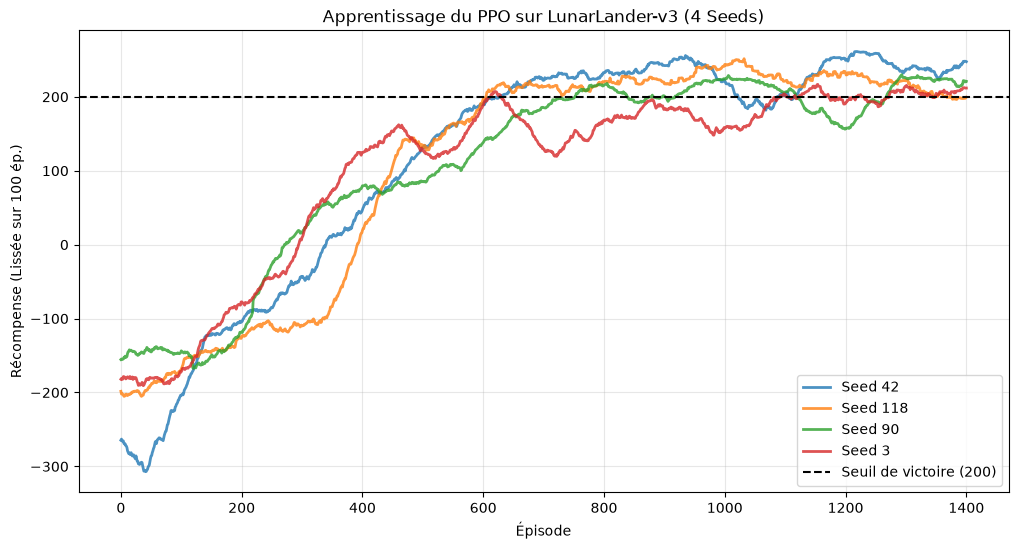

In [29]:
# Couleurs pour différencier facilement nos 4 seeds
couleurs = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

plt.figure(figsize=(12, 6))
for i, (seed, data) in enumerate(historique_seeds.items()):
    moving_avg = np.convolve(data["scores"], np.ones(100) / 100, mode="valid")
    plt.plot(moving_avg, label=f"Seed {seed}", color=couleurs[i], linewidth=2, alpha=0.8)

plt.axhline(y=200, color="black", linestyle="--", label="Seuil de victoire (200)")
plt.xlabel("Épisode")
plt.ylabel("Récompense (Lissée sur 100 ép.)")
plt.title("Apprentissage du PPO sur LunarLander-v3 (4 Seeds)") 
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Statistiques de terminaison et Longueur des épisodes

Dans cette section, nous affichons deux graphiques permettant d'analyser le comportement du module lunaire pendant l'entraînement.

<b>Répartition des raisons de fin :</b>

Nous comptabilisons les différentes manières dont les épisodes se terminent :

- truncated : l'épisode est interrompu parce que la limite de temps est atteinte.
- out_of_viewport : le module sort de la zone visible.
- at_rest : le module est considéré comme ayant atterri.
- crash : le module termine son épisode sans réussir son atterrissage.

Cette répartition permet de suivre l'évolution des résultats et de voir si le nombre d'atterrissages réussis augmente au cours de l'entraînement.

<b>Longueur des épisodes : </b>

Le deuxième graphique représente le nombre de pas effectués avant la fin de chaque épisode.<br>
L'environnement possède une limite de 1000 pas par épisode.<br>
Ce graphique permet d'observer si le modèle apprend à terminer ses épisodes plus efficacement.<br>µ
Il faut cependant prendre en compte les récompenses obtenues : un épisode plus court ne signifie pas nécessairement que le module a réussi son atterrissage.

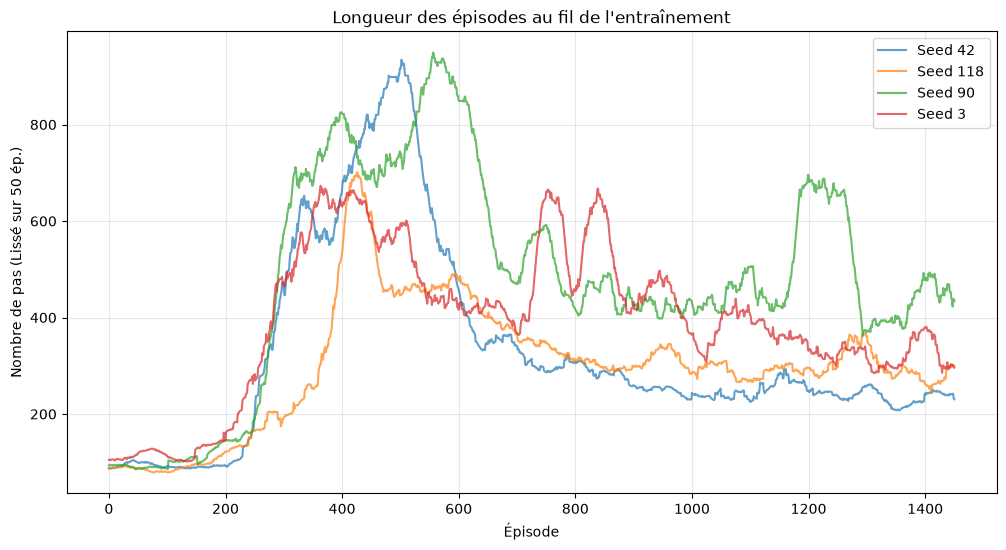

In [30]:
plt.figure(figsize=(12, 6))
for i, (seed, data) in enumerate(historique_seeds.items()):
    moving_avg_len = np.convolve(data["lengths"], np.ones(50) / 50, mode="valid")
    plt.plot(moving_avg_len, label=f"Seed {seed}", color=couleurs[i], alpha=0.7)

plt.xlabel("Épisode")
plt.ylabel("Nombre de pas (Lissé sur 50 ép.)")
plt.title("Longueur des épisodes au fil de l'entraînement")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Les courbes de pertes (Policy Loss, Value Loss) et d'Entropie.

Dans cette section, nous affichons trois indicateurs importants du fonctionnement interne de notre modèle PPO.

<b> Policy Loss : </b>

La Policy Loss représente la fonction de perte associée à l'Actor.<br>
Elle intervient dans l'amélioration de la politique en utilisant les avantages calculés précédemment.<br>
Le mécanisme de clipping permet de limiter les modifications trop importantes de la politique entre deux mises à jour.

<b> Value Loss : </b>

La Value Loss représente l'erreur entre les valeurs estimées par le Critic et les retours calculés grâce au GAE.<br>
Elle utilise une fonction MSE afin d'améliorer progressivement les estimations du Critic.

<b> Entropie :</b>

L'entropie permet de mesurer la diversité de la distribution de probabilités produite par l'Actor.<br>
Une entropie élevée indique que les probabilités sont davantage réparties entre les différentes actions.<br>
À l'inverse, une entropie faible indique que le modèle privilégie davantage certaines actions.<br>
Cet indicateur permet donc d'observer l'évolution de la diversité des choix du modèle au cours de l'entraînement.<br>

Ces trois graphiques permettent de mieux comprendre les mises à jour effectuées par le PPO. Ils doivent cependant être analysés avec les récompenses obtenues : une diminution de la perte ne signifie pas automatiquement que le modèle devient plus performant.

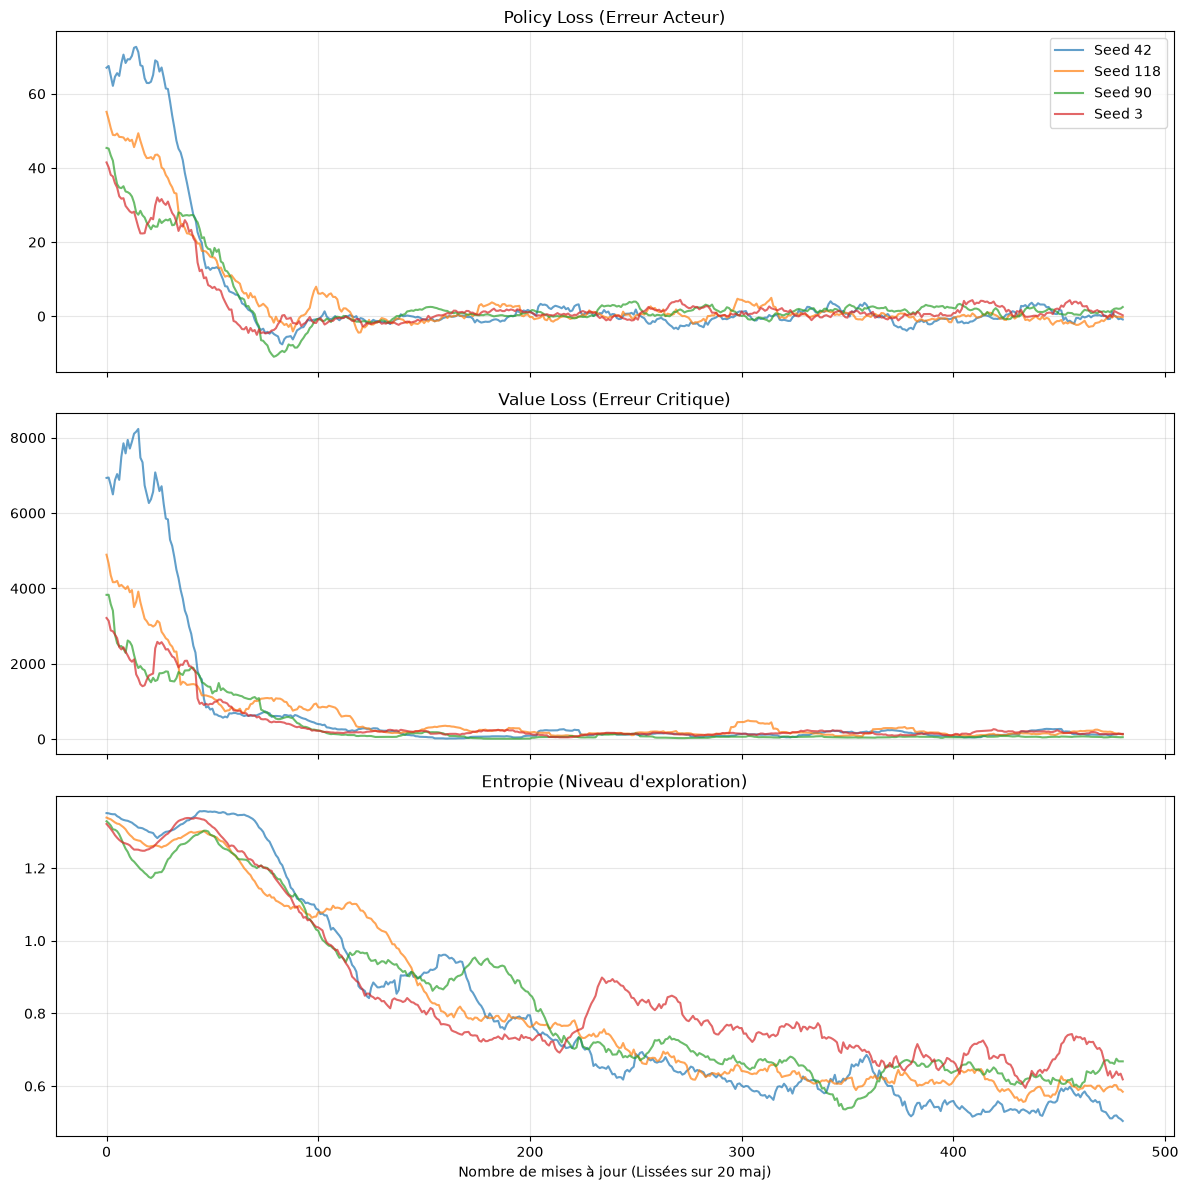

In [31]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

for i, (seed, data) in enumerate(historique_seeds.items()):
    p_loss_liss = np.convolve(data["p_loss"], np.ones(20) / 20, mode="valid")
    v_loss_liss = np.convolve(data["v_loss"], np.ones(20) / 20, mode="valid")
    ent_liss = np.convolve(data["entropy"], np.ones(20) / 20, mode="valid")
    
    ax1.plot(p_loss_liss, label=f"Seed {seed}", color=couleurs[i], alpha=0.7)
    ax2.plot(v_loss_liss, label=f"Seed {seed}", color=couleurs[i], alpha=0.7)
    ax3.plot(ent_liss, label=f"Seed {seed}", color=couleurs[i], alpha=0.7)

ax1.set_title("Policy Loss (Erreur Acteur)")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.set_title("Value Loss (Erreur Critique)")
ax2.grid(True, alpha=0.3)

ax3.set_title("Entropie (Niveau d'exploration)")
ax3.set_xlabel("Nombre de mises à jour (Lissées sur 20 maj)")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# évaluation du modèle sur 100 épisodes

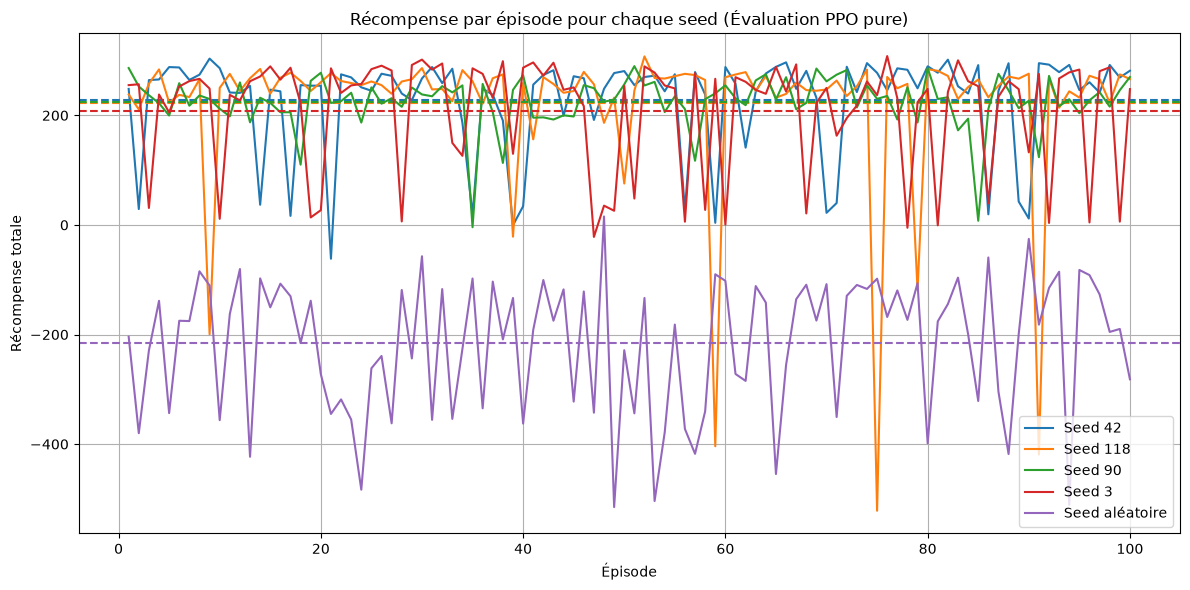

In [ ]:
import os
import torch
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

# Paramètres d'évaluation
eval_episodes = 100
seeds = [42, 118, 90, 3]
couleurs = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

env = gym.make("LunarLander-v3")
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

# agent aléatoire
rewards_aleatoire = []
for _ in range(eval_episodes):
    state, info = env.reset(seed=42)
    total_reward = 0
    done = False
    while not done:
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        total_reward += reward
    rewards_aleatoire.append(total_reward)

episodes_aleatoire = list(range(1, eval_episodes + 1))


# agent ppo
plt.figure(figsize=(12, 6))

for i, seed in enumerate(seeds):
    ppo_agent = PPOAgent(state_dim, action_dim)
    nom_fichier = os.path.join("PTH_PPO", f"lunarlander_ppo_{seed}.pth")
    ppo_agent.policy.load_state_dict(torch.load(nom_fichier))
    ppo_agent.policy.eval() # mode eval
    
    rewards_ppo = []
    
    
    for _ in range(eval_episodes):
        state, info = env.reset()
        total_reward = 0
        done = False
        
        while not done:
            state_tensor = torch.FloatTensor(state).to(device)
            with torch.no_grad():
                action_probs, _ = ppo_agent.policy(state_tensor)
    
                action = torch.argmax(action_probs).item()
                
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total_reward += reward
            state = next_state
            
        rewards_ppo.append(total_reward)
        
    episodes_ppo = list(range(1, eval_episodes + 1))
    
    
    plt.plot(episodes_ppo, rewards_ppo, label=f"Seed {seed}", color=couleurs[i])
    
    
    mean_score = np.mean(rewards_ppo)
    plt.axhline(y=mean_score, color=couleurs[i], linestyle="--")


plt.plot(episodes_aleatoire, rewards_aleatoire, label="Seed aléatoire", color='#9467bd')
plt.axhline(y=np.mean(rewards_aleatoire), color='#9467bd', linestyle="--")


plt.title("Récompense par épisode pour chaque seed (Évaluation PPO pure)")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")


plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

env.close()

### <b><u> Liste des Hyperparamètres </u></b> :


- N_EPISODES : 1500
- Nombre de seeds : 4
- Gamma : 0.999
- GAE Lambda : 0.98
- Learning Rate : 0.0003
- BATCH_SIZE : 64
- EPOCHS : 10
- Clipping Epsilon : 0.2


### <b><u>Justification de leur valeur</u></b> :

- N_EPISODES : 1500 :

Nous avons fixé l'entraînement à 1500 épisodes pour laisser suffisamment de temps à l'agent PPO pour apprendre à contrôler le vaisseau et améliorer ses performances. Cette valeur correspond au nombre d'épisodes exécutés pour chaque seed. Nous utilisons également 4 seeds différentes (42, 118, 90 et 3), afin de comparer plusieurs entraînements et de ne pas dépendre uniquement d'une initialisation aléatoire des poids du réseau.

- Gamma : 0.999 :

Gamma détermine l'importance accordée aux récompenses futures par rapport aux récompenses immédiates. Une valeur proche de 1 encourage l'agent à prendre en compte les conséquences de ses actions sur le long terme. Dans LunarLander, il est important de ne pas uniquement chercher à obtenir une récompense immédiate, mais également de prendre en compte toute la trajectoire du vaisseau jusqu'à son atterrissage. Nous utilisons donc une valeur élevée de 0.999 pour favoriser cette vision à long terme.

- GAE Lambda : 0.98 :

Le paramètre Lambda intervient dans le calcul du GAE (Generalized Advantage Estimation). Celui-ci permet d'estimer si une action a été meilleure ou moins bonne que ce que le Critic avait initialement prévu. Lambda contrôle l'équilibre entre la précision de cette estimation et sa variance. Une valeur élevée prend davantage en compte les récompenses futures, tandis qu'une valeur plus faible privilégie une estimation plus locale. Nous avons choisi 0.98 afin de conserver une bonne prise en compte des conséquences futures tout en stabilisant les estimations des avantages utilisées pour entraîner l'Actor.

- Learning Rate : 0.0003 :

Le learning rate détermine l'importance des modifications apportées aux poids des réseaux Actor et Critic à chaque mise à jour. S'il est trop élevé, l'apprentissage peut devenir instable et les réseaux risquent de modifier trop brutalement leur comportement. À l'inverse, s'il est trop faible, la progression peut être très lente. La valeur de 0.0003 permet de conserver des mises à jour relativement progressives, adaptées à l'apprentissage de PPO.

- BATCH_SIZE : 64 :

Le batch size représente le nombre d'expériences utilisées simultanément pour effectuer une mise à jour des réseaux. Dans notre cas, les expériences sont récupérées dans le Rollout Buffer, puis mélangées et réparties en mini-batchs de 64 éléments. Un batch trop petit peut rendre les mises à jour plus variables, tandis qu'un batch trop important demande davantage de calcul et réduit le nombre de mises à jour possibles pour une même quantité de données. Nous avons retenu 64 afin de disposer de mini-batchs suffisamment importants tout en conservant plusieurs mises à jour par époque.

- EPOCHS : 10:

Le nombre d'epochs correspond au nombre de passages effectués sur les expériences collectées dans le Rollout Buffer lors d'une mise à jour. Avec 10 epochs, l'agent réutilise donc les mêmes expériences dix fois, en mélangeant leur ordre à chaque passage. Cela permet d'exploiter davantage les données collectées sans devoir constamment générer de nouvelles expériences. Un nombre trop élevé pourrait cependant conduire à un apprentissage excessif sur les mêmes données et à des modifications trop importantes de la politique.
- Clipping Epsilon : 0.2:

Dans PPO, epsilon correspond au paramètre de clipping, et non à un taux d'exploration comme dans DQN. Il permet de limiter l'importance des changements de politique entre deux mises à jour. Concrètement, le ratio entre les nouvelles probabilités d'action et les anciennes est limité dans un intervalle allant de 0.8 à 1.2. Cela empêche l'agent de modifier trop brutalement son comportement lorsqu'une action semble particulièrement avantageuse. Cette limitation contribue à rendre l'entraînement plus stable.



# Conclusion et Bilan

Dans cette section, nous allons conclure la partie PPO, résumer les différentes étapes de conception et d'entraînement du modèle, puis faire un bilan général des résultats obtenus.

Le modèle **PPO (Proximal Policy Optimization)** est un algorithme d'apprentissage par renforcement (*Reinforcement Learning*). Il appartient à la famille des méthodes *Policy Gradient* et utilise deux réseaux de neurones complémentaires pour apprendre à prendre des décisions et à évaluer les situations rencontrées.

### Remise en contexte

Notre objectif était d'utiliser cet algorithme afin de faire atterrir un module lunaire dans l'environnement <u>"LunarLander-v3"</u>.

Cet environnement possède 4 actions possibles et renvoie 8 éléments d'observation.

Ses actions sont :

- Ne rien faire.
- Activer le propulseur droit.
- Activer le propulseur gauche.
- Activer le propulseur central.

Ses éléments d'observation sont :

- Sa position horizontale.
- Sa position verticale.
- Sa vitesse horizontale.
- Sa vitesse verticale.
- L'angle de son atterrisseur par rapport à l'horizontale.
- Sa vitesse angulaire.
- Le contact de sa jambe droite avec le sol.
- Le contact de sa jambe gauche avec le sol.

L'entraînement du modèle PPO passe par plusieurs étapes :

- **La création du modèle Actor-Critic**
    - Cette architecture repose sur deux réseaux de neurones complémentaires.
    - L'Actor est chargé de choisir les actions à effectuer en calculant les probabilités associées à chaque action possible.
    - Le Critic évalue l'état actuel du module en estimant la récompense future que celui-ci peut obtenir.
    - Ces deux réseaux travaillent ensemble pour améliorer progressivement la stratégie du modèle.

- **La sélection des actions**
    - Pendant l'entraînement, le modèle utilise une distribution de probabilité pour sélectionner ses actions.
    - Cette méthode lui permet d'explorer différentes possibilités au lieu de toujours choisir l'action qui semble la meilleure.
    - Les probabilités et les actions choisies sont conservées afin de pouvoir comparer l'ancienne stratégie avec la nouvelle pendant la phase d'optimisation.

- **Le Rollout Buffer**
    - Il représente la mémoire temporaire du modèle.
    - Il conserve les expériences obtenues pendant plusieurs épisodes : les états, les actions, les récompenses, les probabilités des actions choisies et les valeurs estimées par le Critic.
    - Ces informations seront ensuite utilisées pour mettre à jour les réseaux de neurones.

- **Le calcul du GAE (Generalized Advantage Estimation)**
    - Cette méthode permet d'estimer l'avantage d'une action, c'est-à-dire de déterminer si elle a été meilleure ou moins bonne que ce que le Critic avait initialement prévu.
    - Elle utilise les récompenses obtenues et les estimations du Critic pour calculer les avantages et les retours.
    - Les paramètres Gamma et Lambda permettent notamment de contrôler la prise en compte des récompenses futures et la manière dont les avantages sont estimés.

- **L'optimisation PPO**
    - Le modèle compare les probabilités des actions obtenues avec l'ancienne et la nouvelle stratégie.
    - Il utilise un mécanisme de clipping pour limiter l'ampleur des changements de stratégie à chaque mise à jour.
    - Cette limitation permet d'éviter que le modèle modifie trop brutalement son comportement.
    - La fonction de perte prend en compte trois éléments : l'amélioration de la stratégie de l'Actor, l'évaluation du Critic et l'entropie, qui encourage le maintien d'une certaine exploration.

Le modèle fonctionne grâce à un système de récompenses fourni par l'environnement. Celui-ci attribue des points positifs ou négatifs selon le comportement du module lunaire.

Les récompenses prennent notamment en compte :

- Une augmentation des points si le module se rapproche du palier d'atterrissage et une diminution s'il s'en éloigne.
- Une augmentation des points si le module se déplace lentement et une diminution s'il va trop vite.
- Une diminution des points si l'atterrisseur est trop incliné par rapport à l'horizontale.
- +10 points si les jambes du module entrent en contact avec le sol.
- -0.03 points pour chaque activation des moteurs latéraux.
- -0.3 points pour chaque activation du moteur central.
- -100 points si le module se crashe.

L'entraînement se déroule sous forme d'épisodes. Dans notre implémentation, chaque épisode peut se terminer de différentes manières :

- Le module se crashe.
- Le module sort de l'écran.
- Le module atterrit correctement.
- L'épisode atteint sa limite de temps.

À chaque épisode, l'environnement est réinitialisé afin que le module puisse apprendre à partir de nouvelles situations.

Pendant l'entraînement, chaque action produit une expérience qui contient plusieurs informations :

- **state** : l'état dans lequel se trouvait le module avant son action.
- **action** : l'action choisie par l'Actor.
- **reward** : la récompense obtenue après cette action.
- **is_terminal** : indique si l'épisode est terminé.
- **certitude** : correspond à l'ancienne log-probabilité de l'action choisie.
- **state_value** : correspond à l'estimation de la valeur de l'état effectuée par le Critic.

Ces expériences sont ensuite regroupées dans le Rollout Buffer afin de calculer les avantages et de mettre à jour les réseaux de neurones.

### Conclusion

En assemblant tous ces éléments dans l'entraînement et en adaptant les hyperparamètres, nous obtenons un modèle PPO capable d'apprendre progressivement une stratégie d'atterrissage.

Pour suivre son évolution, nous avons créé plusieurs graphiques permettant d'observer les récompenses obtenues, leur moyenne glissante, la durée des épisodes, les différentes raisons de terminaison ainsi que l'évolution des pertes de l'Actor et du Critic et de l'entropie.

Ces graphiques permettent de mieux comprendre le comportement du modèle et de vérifier si son apprentissage progresse correctement.

Une fois l'entraînement terminé, nous évaluons le modèle sur 100 épisodes. Durant cette phase, nous désactivons l'exploration aléatoire en sélectionnant systématiquement l'action ayant le score le plus élevé parmi les sorties de l'Actor.

Cela permet d'évaluer la stratégie apprise par le modèle sans effectuer de nouvelles explorations aléatoires.

Nous calculons ensuite la moyenne et l'écart-type des récompenses obtenues, puis affichons leur distribution dans un histogramme. Cela permet de vérifier si le modèle est capable de reproduire ses performances sur plusieurs épisodes et si ses résultats sont suffisamment réguliers.

### Bilan

Notre objectif était d'obtenir un module lunaire capable d'obtenir une récompense moyenne d'au moins 200 points sur 100 épisodes d'évaluation.

L'entraînement PPO nous permet d'étudier une autre approche de l'apprentissage par renforcement que le DQN. Contrairement au DQN, qui apprend à estimer la valeur de chaque action, le PPO apprend directement une stratégie de sélection des actions grâce à son Actor, tout en utilisant son Critic pour évaluer les états rencontrés.

Les résultats de l'évaluation permettent de mesurer les performances réellement obtenues par notre modèle et de vérifier s'il atteint l'objectif fixé.

Enfin, il est important de rappeler que les résultats présentés correspondent à un entraînement PPO. Pour confirmer la stabilité de l'approche, il serait intéressant de répéter l'expérience avec plusieurs graines aléatoires et de comparer les résultats obtenus avec ceux du DQN.